In [44]:
import time
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [45]:
ANIO = 2025
BASE = "https://api.openf1.org/v1"

PILOTOS_ELEGIDOS = [
    "LECLERC",
    "HAMILTON"
]

# Puntos estándar según la posición en carrera
PUNTOS_F1 = {
    1: 25,
    2: 18,
    3: 15,
    4: 12,
    5: 10,
    6: 8,
    7: 6,
    8: 4,
    9: 2,
    10: 1
}

In [46]:
def consultar(endpoint, params=None, intentos=5):
    for intento in range(intentos):
        respuesta = requests.get(
            f"{BASE}/{endpoint}",
            params=params,
            timeout=30
        )

        if respuesta.status_code == 429:
            espera = int(
                respuesta.headers.get("Retry-After", 15)
            )
            espera = max(espera, 5)

            print(
                f"Demasiadas peticiones. "
                f"Esperando {espera} segundos..."
            )
            time.sleep(espera)
            continue

        respuesta.raise_for_status()
        return respuesta.json()

    raise RuntimeError(
        "OpenF1 sigue limitando las peticiones. "
        "Espera un poco y vuelve a ejecutar."
    )



In [47]:
# ==========================================
# 1. OBTENER TODAS LAS CARRERAS DE LA TEMPORADA
# ==========================================
sesiones = pd.DataFrame(
    consultar(
        "sessions",
        {
            "year": ANIO,
            "session_name": "Race"
        }
    )
)

if sesiones.empty:
    raise ValueError("No se encontraron carreras.")

sesiones["date_start"] = pd.to_datetime(
    sesiones["date_start"]
)

sesiones = sesiones.sort_values(
    "date_start"
).reset_index(drop=True)

# Guardar todas las carreras para calcular el acumulado
todas_las_carreras = sesiones.copy()

# Seleccionar las últimas carreras que aparecerán en el gráfico
ultimas = sesiones.copy()

print(f"Temporada: {ANIO}")
print(f"Carreras de la temporada: {len(todas_las_carreras)}")
print(f"Carreras que aparecerán en el gráfico: {NUM_GP}")

print("\nGrandes Premios mostrados:")
print(
    ultimas[
        ["country_name", "date_start"]
    ].to_string(index=False)
)



Temporada: 2025
Carreras de la temporada: 24
Carreras que aparecerán en el gráfico: 5

Grandes Premios mostrados:
        country_name                date_start
           Australia 2025-03-16 04:00:00+00:00
               China 2025-03-23 07:00:00+00:00
               Japan 2025-04-06 05:00:00+00:00
             Bahrain 2025-04-13 15:00:00+00:00
        Saudi Arabia 2025-04-20 17:00:00+00:00
       United States 2025-05-04 20:00:00+00:00
               Italy 2025-05-18 13:00:00+00:00
              Monaco 2025-05-25 13:00:00+00:00
               Spain 2025-06-01 13:00:00+00:00
              Canada 2025-06-15 18:00:00+00:00
             Austria 2025-06-29 13:00:00+00:00
      United Kingdom 2025-07-06 14:00:00+00:00
             Belgium 2025-07-27 13:00:00+00:00
             Hungary 2025-08-03 13:00:00+00:00
         Netherlands 2025-08-31 13:00:00+00:00
               Italy 2025-09-07 13:00:00+00:00
          Azerbaijan 2025-09-21 11:00:00+00:00
           Singapore 2025-10-05 12:00:00

In [48]:
# ==========================================
# 2. OBTENER LOS RESULTADOS DE CADA CARRERA
# ==========================================
resultados = []

for _, sesion in todas_las_carreras.iterrows():

    print(
        f"\nConsultando {sesion['country_name']}..."
    )

    respuesta = consultar(
        "session_result",
        {
            "session_key": int(sesion["session_key"])
        }
    )

    if not respuesta:
        print("No hay resultados para esta carrera.")
        time.sleep(2)
        continue

    df = pd.DataFrame(respuesta)

    if "position" not in df.columns:
        raise ValueError(
            "No se encontró la columna 'position' "
            "en los resultados."
        )

    if "driver_number" not in df.columns:
        raise ValueError(
            "No se encontró la columna 'driver_number'."
        )

    # Convertir la posición a número
    df["posicion"] = pd.to_numeric(
        df["position"],
        errors="coerce"
    )

    # Calcular los puntos según la posición final
    df["puntos"] = (
        df["posicion"]
        .map(PUNTOS_F1)
        .fillna(0)
    )

    # No asignar puntos a pilotos que no tomaron la salida
    if "dns" in df.columns:
        no_salieron = (
            df["dns"]
            .astype(str)
            .str.lower()
            .isin(["true", "1"])
        )
        df.loc[no_salieron, "puntos"] = 0

    df["driver_number"] = (
        df["driver_number"].astype(str)
    )

    df["GP"] = int(sesion["session_key"])
    df["pais"] = sesion["country_name"]
    df["fecha"] = sesion["date_start"]

    resultados.append(
        df[
            [
                "driver_number",
                "posicion",
                "puntos",
                "GP",
                "pais",
                "fecha"
            ]
        ]
    )

    # Pausa para reducir el riesgo de límite de solicitudes
    time.sleep(3)

if not resultados:
    raise ValueError(
        "No se encontraron resultados de carrera."
    )

datos = pd.concat(
    resultados,
    ignore_index=True
)




Consultando Australia...

Consultando China...

Consultando Japan...

Consultando Bahrain...

Consultando Saudi Arabia...

Consultando United States...

Consultando Italy...

Consultando Monaco...

Consultando Spain...

Consultando Canada...

Consultando Austria...

Consultando United Kingdom...

Consultando Belgium...

Consultando Hungary...

Consultando Netherlands...

Consultando Italy...

Consultando Azerbaijan...

Consultando Singapore...

Consultando United States...

Consultando Mexico...

Consultando Brazil...

Consultando United States...

Consultando Qatar...

Consultando United Arab Emirates...


In [49]:
# ==========================================
# 3. OBTENER LOS NOMBRES DE LOS PILOTOS
# ==========================================
# Consultar los pilotos de una sesión reciente de la temporada
sesion_referencia = int(
    todas_las_carreras.iloc[-1]["session_key"]
)

pilotos = pd.DataFrame(
    consultar(
        "drivers",
        {
            "session_key": sesion_referencia
        }
    )
)

if pilotos.empty:
    raise ValueError(
        "No se encontraron datos de pilotos."
    )

pilotos["driver_number"] = (
    pilotos["driver_number"].astype(str)
)

if "full_name" not in pilotos.columns:
    raise ValueError(
        "No se encontró la columna 'full_name'."
    )

nombres = pilotos[
    ["driver_number", "full_name"]
].drop_duplicates(
    "driver_number"
)

datos = datos.merge(
    nombres,
    on="driver_number",
    how="left"
)

datos["piloto"] = datos["full_name"].fillna(
    datos["driver_number"]
)


In [50]:
# ==========================================
# 4. FILTRAR LOS TRES PILOTOS
# ==========================================
datos = datos[
    datos["piloto"].str.upper().apply(
        lambda nombre: any(
            apellido in nombre
            for apellido in PILOTOS_ELEGIDOS
        )
    )
].copy()

if datos.empty:
    raise ValueError(
        "No se encontraron Verstappen, Norris y Piastri. "
        "Comprueba los nombres devueltos por OpenF1."
    )

print("\nPilotos incluidos:")
print(
    datos["piloto"].drop_duplicates().to_list()
)


Pilotos incluidos:
['Charles LECLERC', 'Lewis HAMILTON']


In [51]:
# ==========================================
# 5. CREAR LA TABLA DE PUNTOS ACUMULADOS
# ==========================================
orden_gps = (
    todas_las_carreras["session_key"]
    .astype(int)
    .tolist()
)

tabla = datos.pivot_table(
    index="piloto",
    columns="GP",
    values="puntos",
    aggfunc="sum",
    fill_value=0
)

# Incluir todas las carreras en orden cronológico
tabla = tabla.reindex(
    columns=orden_gps,
    fill_value=0
)

# Sumar los puntos de forma acumulativa
tabla_acumulada = tabla.cumsum(axis=1)

# Conservar solo las últimas carreras para el gráfico
tabla_grafico = tabla_acumulada.copy()

# Ordenar por puntos acumulados al final del periodo
tabla_grafico = tabla_grafico.loc[
    tabla_grafico.iloc[:, -1]
    .sort_values(ascending=False)
    .index
]

etiquetas = ultimas["country_name"].tolist()

print("\nPuntos acumulados al finalizar cada GP:")
tabla_mostrar = tabla_grafico.copy()
tabla_mostrar.columns = etiquetas
print(tabla_mostrar)



Puntos acumulados al finalizar cada GP:
                 Australia  China  Japan  Bahrain  Saudi Arabia  \
piloto                                                            
Charles LECLERC        4.0    4.0   16.0     28.0          43.0   
Lewis HAMILTON         1.0    1.0    7.0     17.0          23.0   

                 United States  Italy  Monaco  Spain  Canada  ...  \
piloto                                                        ...   
Charles LECLERC           49.0   57.0    75.0   90.0   100.0  ...   
Lewis HAMILTON            27.0   39.0    49.0   57.0    65.0  ...   

                 Netherlands  Italy  Azerbaijan  Singapore  United States  \
piloto                                                                      
Charles LECLERC        142.0  154.0       156.0      164.0          179.0   
Lewis HAMILTON          95.0  103.0       107.0      111.0          123.0   

                 Mexico  Brazil  United States  Qatar  United Arab Emirates  
piloto                    

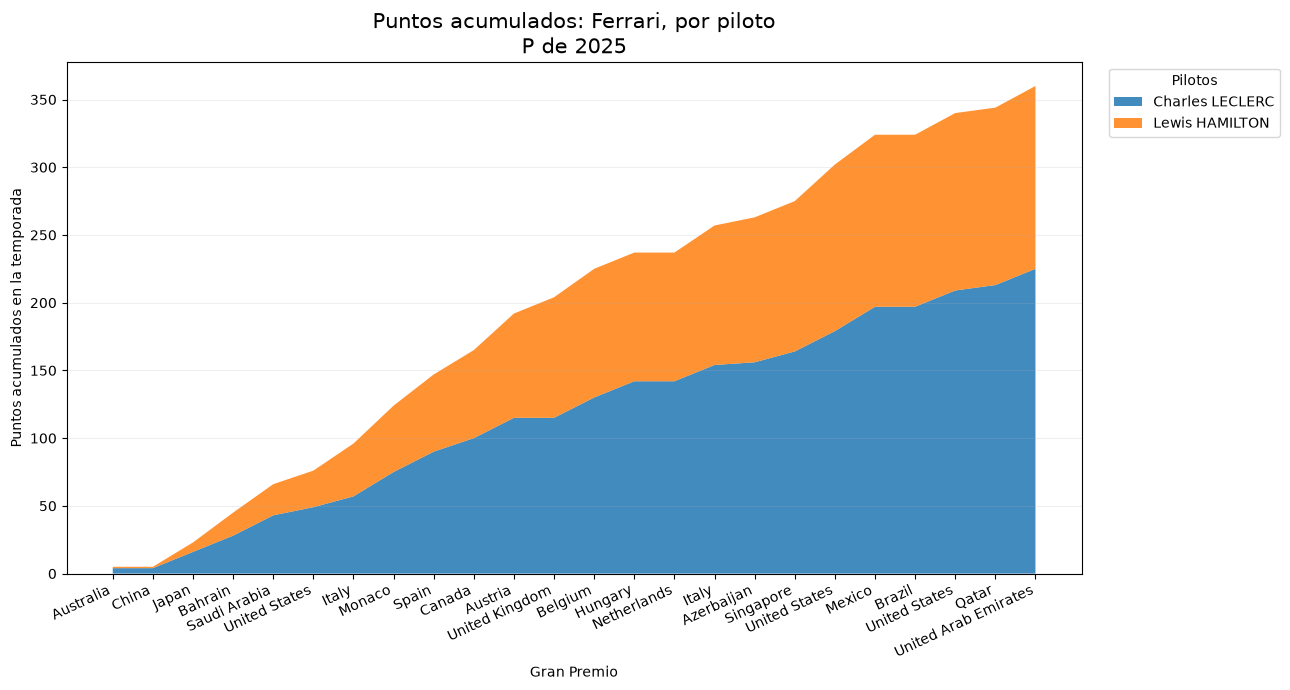

In [52]:
# ==========================================
# 6. CREAR EL GRÁFICO
# ==========================================
fig, ax = plt.subplots(figsize=(13, 7))

ax.stackplot(
    range(len(etiquetas)),
    tabla_grafico.values,
    labels=tabla_grafico.index,
    baseline="zero",
    alpha=0.85
)

ax.set_title(
    f"Puntos acumulados: Ferrari, por piloto\n"
    f"P de {ANIO}",
    fontsize=15
)

ax.set_xlabel("Gran Premio")
ax.set_ylabel("Puntos acumulados en la temporada")

ax.set_xticks(
    range(len(etiquetas))
)

ax.set_xticklabels(
    etiquetas,
    rotation=25,
    ha="right"
)

ax.set_ylim(bottom=0)

ax.legend(
    title="Pilotos",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

ax.grid(
    axis="y",
    alpha=0.2
)

fig.tight_layout()

In [54]:
# ==========================================
# 7. GUARDAR EL GRÁFICO
# ==========================================
ruta = (
    Path.cwd()
    / f"puntos_acumulados_ferrari_temporada_{ANIO}.png"
)

fig.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight"
)

plt.show()